<a href="https://colab.research.google.com/github/SrEffry/Mamografias/blob/main/03_eda_imagenes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 · EDA de imágenes (recortes ROI)

> **Prototipo académico; no apto para diagnóstico ni decisiones clínicas.**

Qué hace este notebook, sobre las 211 lesiones disponibles:
1. Comprueba que las particiones guardadas son las de la **semilla 42** (146 / 37 / 28).
2. Cuenta las vistas **CC/MLO** del subconjunto.
3. Lee el encabezado y los píxeles de cada recorte y verifica que el `PatientID` del DICOM coincide con el `lesion_id` (comprueba el cruce por UID de serie y la regla del área).
4. Busca **duplicados** por hash de píxeles (también prueba que los píxeles se leen bien).
5. Describe la **resolución** (alto, ancho, relación de aspecto) por clase.
6. Muestra **ejemplos** benignos y malignos, solo del conjunto de entrenamiento.

Entrada: `resultados/lesiones_disponibles.csv` y `resultados/particiones/*.csv`. Sin `force=True`.

In [ ]:
!pip install -q pydicom

In [ ]:
# Montar Drive y fijar rutas (las mismas en todos los notebooks)
from google.colab import drive
drive.mount('/content/drive')

import os, sys
BASE    = "/content/drive/MyDrive/Aprendizaje final"
DATA    = f"{BASE}/Csv"
RES     = f"{BASE}/resultados"
SRC     = f"{BASE}/src"
PART    = f"{RES}/particiones"
PNG     = f"{BASE}/procesadas_224"     # recortes preprocesados (no van a Git)
MODELOS = f"{BASE}/modelos"            # checkpoints .pt (no van a Git)
for p in [DATA, RES, SRC, PART]:
    assert os.path.exists(p), f"No existe: {p}"
sys.path.insert(0, SRC)

Mounted at /content/drive


In [ ]:
import hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pydicom
from tqdm.auto import tqdm

disp = pd.read_csv(f"{RES}/lesiones_disponibles.csv")
part = pd.concat([pd.read_csv(f"{PART}/{s}.csv") for s in ["train", "val", "test"]],
                 ignore_index=True)
print(open(f"{PART}/reporte_particion.txt", encoding="utf-8").read())

assert len(disp) == 211 and disp.lesion_id.is_unique
assert set(disp.lesion_id) == set(part.lesion_id), "Las particiones no corresponden a las 211 lesiones"
d = disp.merge(part[["lesion_id", "split", "image view", "left or right breast"]], on="lesion_id")

tam = d.split.value_counts().to_dict()
print("Tamaños:", tam)
assert tam == {"train": 146, "val": 37, "test": 28}, "OJO: estos CSV NO son la partición de la semilla 42"

Modo: propio | semilla: 42 | StratifiedGroupKFold
train    146 lesiones |   74 pacientes |   64 malignas /   82 benignas (43.8 % malignas)
val       37 lesiones |   16 pacientes |   10 malignas /   27 benignas (27.0 % malignas)
test      28 lesiones |   15 pacientes |   11 malignas /   17 benignas (39.3 % malignas)
Pacientes solapados -> train&val: 0, train&test: 0, val&test: 0
Pacientes con lesiones de ambas clases: 1
ADVERTENCIA: val tiene solo 10 lesiones malignas; la sensibilidad será muy inestable (usar intervalos de confianza).
ADVERTENCIA: test tiene solo 11 lesiones malignas; la sensibilidad será muy inestable (usar intervalos de confianza).

Tamaños: {'train': 146, 'val': 37, 'test': 28}


## Vistas CC/MLO del subconjunto

In [ ]:
print(pd.crosstab(d.split, d["image view"], margins=True), "\n")
print(pd.crosstab(d["image view"], d.label.map({0: "benigna", 1: "maligna"}), margins=True))

image view   CC  MLO  All
split                    
test         12   16   28
train        72   74  146
val          20   17   37
All         104  107  211 

label       benigna  maligna  All
image view                       
CC               61       43  104
MLO              65       42  107
All             126       85  211


## Encabezado y píxeles de cada recorte

In [ ]:
filas = []
for r in tqdm(d.itertuples(), total=len(d)):
    ds = pydicom.dcmread(r.crop_path)          # sin force=True
    px = ds.pixel_array
    pid = str(ds.get("PatientID", ""))         # p. ej. Mass-Training_P_02092_LEFT_CC_1
    filas.append(dict(
        lesion_id=r.lesion_id, pid_dicom=pid,
        id_coincide=(pid.split("_", 1)[-1] == r.lesion_id),
        serie_desc=str(ds.get("SeriesDescription", "")),
        fotometria=str(ds.get("PhotometricInterpretation", "")),
        bits=int(ds.get("BitsStored", 0)), dtype=str(px.dtype),
        alto=px.shape[0], ancho=px.shape[1],
        vmin=int(px.min()), vmax=int(px.max()),
        md5=hashlib.md5(px.tobytes()).hexdigest()))

img = pd.DataFrame(filas).merge(d[["lesion_id", "patient_id", "label", "split"]], on="lesion_id")
img["relacion"] = img.ancho / img.alto
print("Recortes leídos:", len(img))

  0%|          | 0/211 [00:00<?, ?it/s]

Recortes leídos: 211


In [ ]:
print("PatientID del DICOM coincide con lesion_id:", int(img.id_coincide.sum()), "de", len(img))
print(img.loc[~img.id_coincide, ["lesion_id", "pid_dicom"]].to_string())
print("\nSeriesDescription:", img.serie_desc.value_counts().to_dict())
print("PhotometricInterpretation:", img.fotometria.value_counts().to_dict())
print("BitsStored:", img.bits.value_counts().to_dict(), "| dtype:", img.dtype.value_counts().to_dict())
print("Recortes constantes (min = max):", int((img.vmin == img.vmax).sum()))
print("Rango de valores: min", img.vmin.min(), "| max", img.vmax.max())

PatientID del DICOM coincide con lesion_id: 211 de 211
Empty DataFrame
Columns: [lesion_id, pid_dicom]
Index: []

SeriesDescription: {'cropped images': 211}
PhotometricInterpretation: {'MONOCHROME2': 211}
BitsStored: {16: 211} | dtype: {'uint16': 211}
Recortes constantes (min = max): 0
Rango de valores: min 0 | max 65535


## Duplicados (hash MD5 de los píxeles)

In [ ]:
dup = img[img.md5.duplicated(keep=False)].sort_values("md5")
print("Recortes con píxeles idénticos a otro:", len(dup))
print(dup[["lesion_id", "patient_id", "split", "label"]].to_string())
# Si dos recortes idénticos estuvieran en particiones distintas, habría fuga.
print("Grupos de duplicados repartidos en más de una partición:",
      int((dup.groupby("md5").split.nunique() > 1).sum()) if len(dup) else 0)

Recortes con píxeles idénticos a otro: 0
Empty DataFrame
Columns: [lesion_id, patient_id, split, label]
Index: []
Grupos de duplicados repartidos en más de una partición: 0


## Resolución de los recortes

clase           benigna  maligna
alto     count   126.00    85.00
         mean    340.32   375.61
         std     120.32   145.55
         min     132.00   182.00
         25%     256.25   265.00
         50%     316.50   341.00
         75%     409.75   475.00
         max     839.00   812.00
ancho    count   126.00    85.00
         mean    342.64   373.02
         std     118.38   123.86
         min     156.00   195.00
         25%     252.00   270.00
         50%     325.00   346.00
         75%     409.00   461.00
         max     758.00   720.00
relacion count   126.00    85.00
         mean      1.02     1.02
         std       0.16     0.17
         min       0.51     0.59
         25%       0.93     0.89
         50%       1.04     1.03
         75%       1.13     1.09
         max       1.39     1.54

Recortes con algún lado < 224 px (se agrandan al redimensionar): 38
Recortes con relación de aspecto fuera de 0.8-1.25: 32 de 211


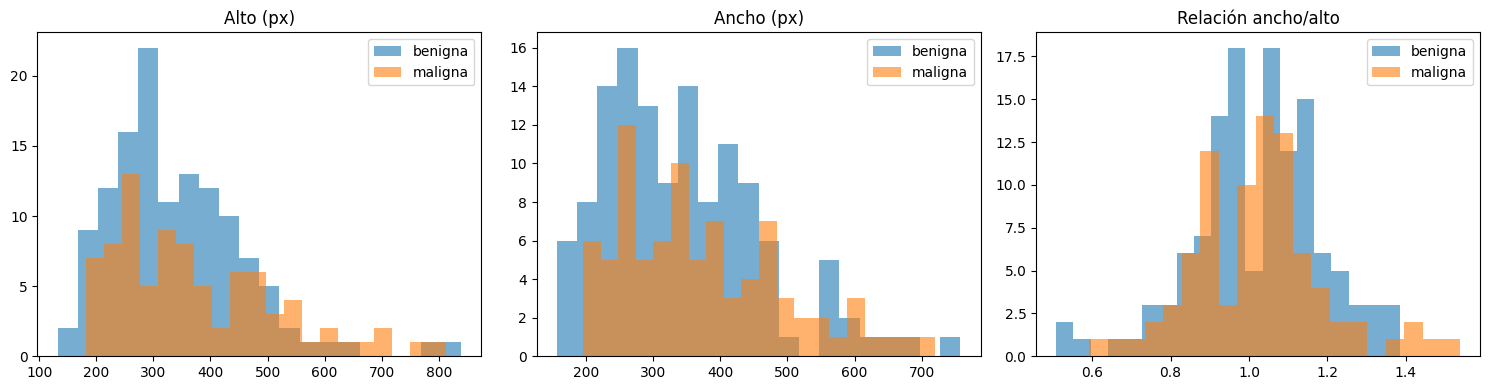

In [ ]:
img["clase"] = img.label.map({0: "benigna", 1: "maligna"})
print(img.groupby("clase")[["alto", "ancho", "relacion"]].describe().T.round(2))

print("\nRecortes con algún lado < 224 px (se agrandan al redimensionar):",
      int((img[["alto", "ancho"]].min(axis=1) < 224).sum()))
print("Recortes con relación de aspecto fuera de 0.8-1.25:",
      int(((img.relacion < 0.8) | (img.relacion > 1.25)).sum()), "de", len(img))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for c in ["benigna", "maligna"]:
    s = img[img.clase == c]
    ax[0].hist(s.alto, bins=20, alpha=.6, label=c)
    ax[1].hist(s.ancho, bins=20, alpha=.6, label=c)
    ax[2].hist(s.relacion, bins=20, alpha=.6, label=c)
for a, t in zip(ax, ["Alto (px)", "Ancho (px)", "Relación ancho/alto"]):
    a.set_title(t); a.legend()
plt.tight_layout()
plt.savefig(f"{RES}/eda_imagenes_resolucion.png", dpi=120, bbox_inches="tight")
plt.show()

## Ejemplos por clase (solo entrenamiento)

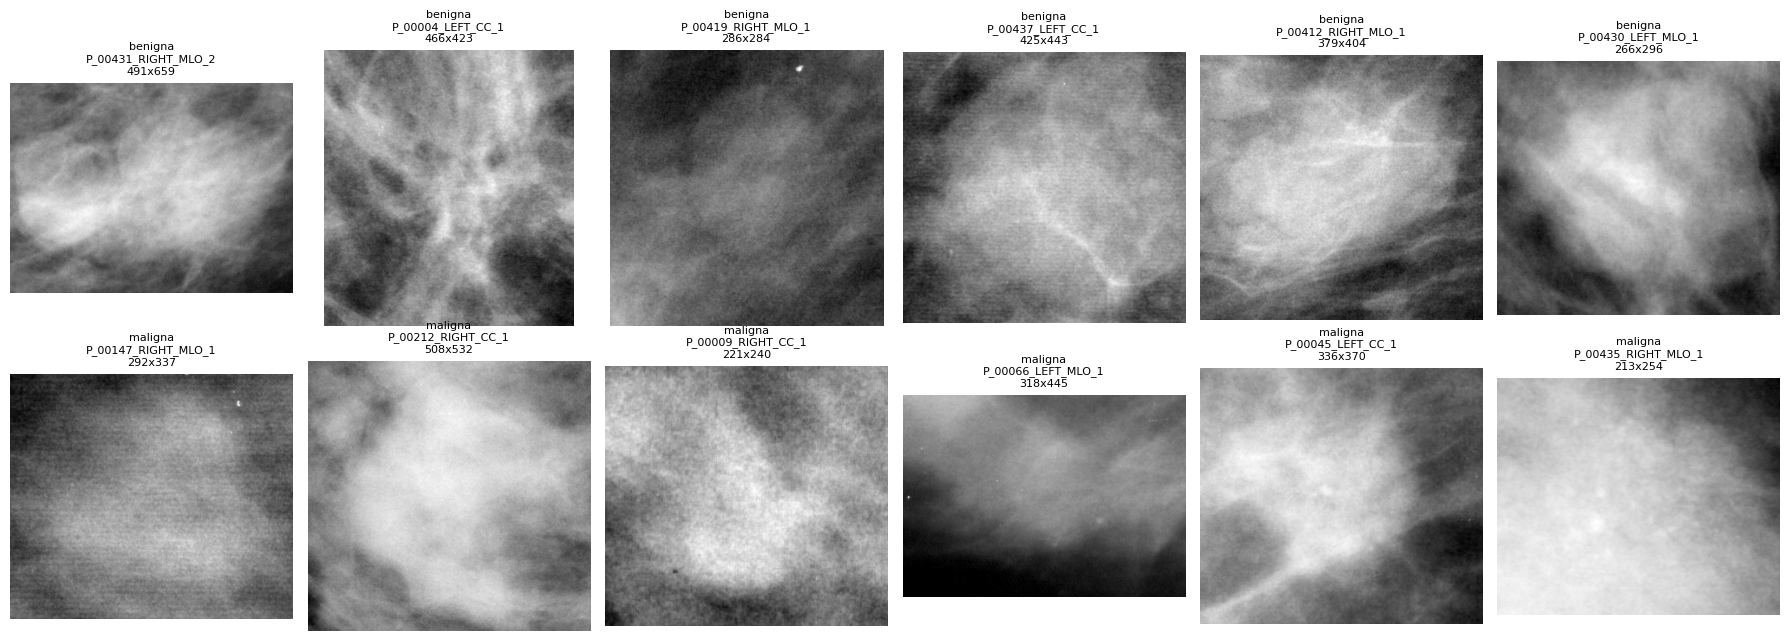

In [ ]:
ej = pd.concat([g.sample(6, random_state=42)
                for _, g in img[img.split == "train"].groupby("clase")])
ruta = disp.set_index("lesion_id").crop_path

fig, ax = plt.subplots(2, 6, figsize=(18, 6.5))
for a, r in zip(ax.ravel(), ej.itertuples()):
    a.imshow(pydicom.dcmread(ruta[r.lesion_id]).pixel_array, cmap="gray")
    a.set_title(f"{r.clase}\n{r.lesion_id}\n{r.alto}x{r.ancho}", fontsize=8)
    a.axis("off")
plt.tight_layout()
plt.savefig(f"{RES}/ejemplos_clases.png", dpi=110, bbox_inches="tight")
plt.show()

In [ ]:
# Resumen sin rutas de Drive (se puede subir a Git)
img.drop(columns=["clase"]).to_csv(f"{RES}/resumen_eda_imagenes.csv", index=False)
print(sorted(os.listdir(RES)))

['archivos_ilegibles.csv', 'curvas_entrenamiento.png', 'eda_imagenes_resolucion.png', 'eda_tabular.png', 'ejemplos_clases.png', 'errores_resnet18_val.png', 'historial_baseline.csv', 'historial_resnet18.csv', 'lesiones_descargadas.txt', 'lesiones_disponibles.csv', 'matriz_confusion_resnet18_val.png', 'metricas_val.csv', 'particiones', 'pred_val_baseline.csv', 'pred_val_resnet18.csv', 'preprocesamiento_ejemplos.png', 'registro_experimentos.csv', 'resumen_eda_imagenes.csv', 'umbrales_val_baseline.csv', 'umbrales_val_resnet18.csv']


In [ ]:
!pip freeze | grep -iE "^(torch|torchvision|pydicom|pandas|numpy|scikit-learn|matplotlib|opencv-python-headless|pillow|tqdm)=="

matplotlib==3.10.0
numpy==2.4.6
opencv-python-headless==5.0.0.93
pandas==2.2.3
pillow==11.3.0
scikit-learn==1.6.1
torch==2.14.1+cu130
torchvision==0.29.1+cu130
tqdm==4.67.3
